# 03 · Stage 2: sentiment (Task 2, measurement)

**Purpose:** show how sentiment is measured for every call, how stable it is, and how it compares with the dataset's own labels.  
**Decisions implemented:** D2, D2a, D7, D8 (anchors v1).  
**Inputs → outputs:** `prompts/stage2_v1.md`, `outputs/stage2/`, `outputs/stage12_metrics.json` → tables and charts. What the numbers mean is in notebook 04.

*Run from the project root or from `notebooks/`; nothing is written, and no model is called (replay mode).*

In [1]:
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
from ti import nbhelpers as nb
nb.setup()
print("replay mode: no network, no API key, no spend")

replay mode: no network, no API key, no spend


## The approach (D2, D2a) and why

The dataset already ships a sentiment score and per-sentence labels, but they are the output of an upstream AI system, and the score agrees with its own sentence labels
almost perfectly, so they are **not independent evidence**. Stage 2 therefore scores each call itself, from the transcript only, in **one structured LLM pass**:

- a **whole-call score 1 to 5** against written anchors, defined for **all 100 calls** (the number compared across call types; internal calls have no customer);
- a **customer-side score** as an extra for calls with a customer;
- a **label for every turn** and a **start vs end trajectory**;
- one **verbatim evidence quote**.

The scorer never sees the title, the call type, or any provided field. It is one pinned model and prompt version for all calls, because a trend is only real if the same method measured every point.
Rejected: a word list (technical vocabulary like "outage" reads negative regardless of mood), two separate passes, a pretrained classifier (no evidence quotes), and customer-side as the primary number (undefined for internal calls).

## The anchors (frozen, D8)

Written from what the 1 to 5 scale should *mean*, with observable cues, **not tuned to the provided score**.

In [2]:
body = nb.prompt_body("stage2_v1")
print(body[body.index("Score the TONE"): body.index("Rules:")].strip())

Score the TONE of the speakers, not how serious the topic is.

Whole-call score (call_score, all speakers, 1 to 5). Anchors:
- 5 (Warm): At least one speaker shows clear enthusiasm, delight, praise or gratitude beyond courtesy (for example "really excited", "this is exactly what we needed"), and this recurs across the call. No complaint and no unresolved problem. The call ends with mutual positivity or a firm positive next step. Borderline: A friendly planning call with a single enthusiastic remark is a 4, not a 5. A 5 needs enthusiasm to be a recurring feature of the call.
- 4 (Constructive): Cooperative and friendly. May include a small concern, a minor delay, or a question that is answered smoothly. Light appreciation ("thanks, that helps"). The call ends agreed and settled. Borderline: A problem is raised, fixed during the call, and the speaker says they are glad: 4, because relief counts as positive. If the frustration before the fix was strong and repeated, score 3.5.
- 3 (Neutra

The rules that make a score checkable (technical words are topic not mood; courtesy is neutral; judge intended meaning; the end of the call matters; how turns and the trajectory are labelled):

In [3]:
print(body[body.index("Rules:"): body.index("Illustrative example A")].strip())

Rules:
1. Technical words are topic, not mood. Words such as outage, failure, breach, error, down or critical describe the subject. They do not make a turn negative. A turn is negative only when the speaker expresses frustration, worry, tension, blame or dissatisfaction.
2. Courtesy is neutral. Greetings, thanks, "I understand", "let me look into that" and protocol apologies ("I'm sorry for the inconvenience") are neutral. A turn is positive only if it shows appreciation beyond courtesy, enthusiasm, praise, agreement with evident satisfaction, or relief. A staff apology that itself shows alarm or distress is negative.
3. Sarcasm and understatement. Judge the intended meaning, not the literal words. "Great, another outage" is negative. Understatement ("it's a bit of a problem" about a total loss of service) is read at its real weight.
4. Resolved versus unresolved. The end of the call matters. A problem that is fixed during the call and met with relief lifts the tone; a problem still op

## Results

All 100 calls were scored: status `ok`, attempts `{'1': 100}` (one attempt each). Per-turn labels complete on 100 of 100; evidence quotes exact on 100 of 100; quotes within the 25-word limit on 88 of 100. A customer-side score exists for 70 calls (those with a customer).

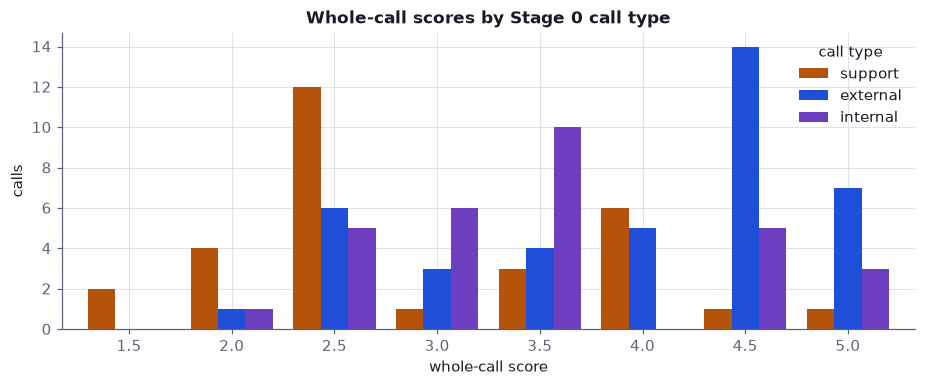

type,calls,our_call_score,our_customer_score,provided_score
support,30,2.93,2.83,2.83
external,40,3.95,3.85,3.85
internal,30,3.50,–,3.42


62% of whole-call scores are half steps (a stated tie-break: when torn between two levels and a problem is still unresolved at the end, take the lower).

In [4]:
c = nb.calls()
m = nb.read_json("outputs/stage12_metrics.json")
s2 = m["stage2"]
nb.md(f"All {s2['n']} calls were scored: status `{', '.join(s2['status'])}`, attempts `{s2['attempts']}` (one attempt each). "
      f"Per-turn labels complete on {s2['per_turn_complete']} of {s2['n']}; evidence quotes exact on {s2['quote_exact']} of {s2['n']}; "
      f"quotes within the 25-word limit on {s2['quote_within_25_words']} of {s2['n']}. "
      f"A customer-side score exists for {int(c.customer_score.notna().sum())} calls (those with a customer).")
dist = pd.crosstab(c.call_score, c.type)[nb.TYPES]
ax = dist.plot.bar(color=[nb.TYPE_COLORS[t] for t in nb.TYPES], figsize=(8.5, 3.6), width=0.8)
ax.set_xlabel("whole-call score"); ax.set_ylabel("calls"); ax.set_title("Whole-call scores by Stage 0 call type")
ax.legend(title="call type", frameon=False); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
tbl = (c.groupby("type").agg(calls=("call_score", "size"), our_call_score=("call_score", "mean"),
                              our_customer_score=("customer_score", "mean"), provided_score=("provided_score", "mean"))
       .reindex(nb.TYPES).round(2).reset_index())
nb.table(tbl)
nb.md(f"{nb.pct(s2['distribution']['half_step_share'], 0)} of whole-call scores are half steps (a stated tie-break: when torn between two levels and a problem is still unresolved at the end, take the lower).")

## Stability: same method, run twice

A second independent pass over a seeded sample of 20 calls (stratified by call type). Temperature 0 does not make these models repeat exactly (notebook 06), so this measures how much the answers move.

In [5]:
ss = m["stage2_stability"]
nb.table(pd.DataFrame([
    {"measure": "calls in the sample", "value": ss["n"]},
    {"measure": "whole-call score: mean absolute difference between runs", "value": round(ss["call_score_mad"], 3)},
    {"measure": "whole-call score: calls with an identical score", "value": f"{ss['call_score_identical']} of {ss['n']}"},
    {"measure": "whole-call score: largest difference", "value": ss["max_call_score_diff"]},
    {"measure": "customer-side score: mean absolute difference", "value": round(ss["customer_score_mad"], 3)},
    {"measure": "trajectory start / end: mean absolute difference", "value": f"{ss['traj_start_mad']:.2f} / {ss['traj_end_mad']:.2f}"},
    {"measure": f"per-turn label agreement ({ss['per_turn_n']} turns)", "value": nb.pct(ss["per_turn_label_agreement"])},
]))

measure,value
calls in the sample,20
whole-call score: mean absolute difference between runs,0.075
whole-call score: calls with an identical score,17 of 20
whole-call score: largest difference,0.5
customer-side score: mean absolute difference,0.143
trajectory start / end: mean absolute difference,0.00 / 0.10
per-turn label agreement (860 turns),92.9%


## Consistency with the dataset's own labels (not accuracy)

The provided labels are an upstream AI output, so agreement here means *consistent with*, not *correct*. It is still informative about **where we differ systematically**.

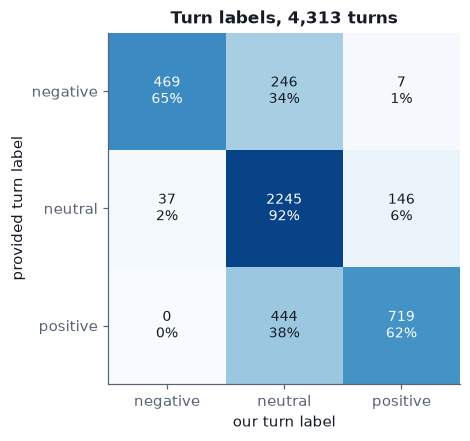

Overall agreement **79.6%**. By call type: support 82.2% (1,191 turns), external 76.6% (1,821 turns), internal 81.5% (1,301 turns).  
We label 68.1% of turns neutral against 56.3% in the provided labels: 444 turns the provided labels call positive, we call neutral. This is mostly the *courtesy is neutral* rule (D8), a design choice, not a bug (notebook 04, H5).

In [6]:
sl = s2["sentence_level_agreement_with_provided"]
cm = pd.DataFrame(sl["overall"]["confusion_rows_provided_cols_model"]).T.loc[["negative", "neutral", "positive"], ["negative", "neutral", "positive"]]
rowpct = cm.div(cm.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(5.2, 4.1))
ax.imshow(rowpct.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(cm.columns); ax.set_yticks(range(3)); ax.set_yticklabels(cm.index)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm.values[i, j]}\n{rowpct.values[i, j]:.0%}", ha="center", va="center", color="white" if rowpct.values[i, j] > 0.5 else "#161b26", fontsize=9)
ax.set_xlabel("our turn label"); ax.set_ylabel("provided turn label"); ax.set_title(f"Turn labels, {sl['overall']['n']:,} turns")
ax.grid(False); plt.tight_layout(); plt.show()
n = cm.values.sum()
nb.md(f"Overall agreement **{nb.pct(sl['overall']['agreement'])}**. By call type: " +
      ", ".join(f"{t} {nb.pct(sl[t]['agreement'])} ({sl[t]['n']:,} turns)" for t in nb.TYPES) + ".  \n"
      f"We label {nb.pct(cm['neutral'].sum() / n)} of turns neutral against {nb.pct(cm.loc['neutral'].sum() / n)} in the provided labels: "
      f"{cm.loc['positive', 'neutral']} turns the provided labels call positive, we call neutral. This is mostly the *courtesy is neutral* rule (D8), a design choice, not a bug (notebook 04, H5).")

### Whole-call score against the provided score

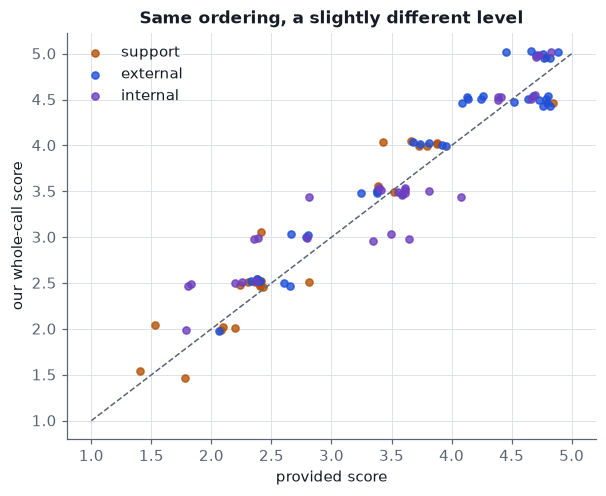

group,calls,pearson,spearman,mean abs difference
all,100,0.963,0.959,0.234
external,40,0.967,0.917,0.223
internal,30,0.928,0.927,0.290
support,30,0.971,0.956,0.193


In [7]:
cs = s2["call_score_vs_provided_score"]
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
for t in nb.TYPES:
    d = c[c.type == t]
    ax.scatter(d.provided_score + rng.normal(0, 0.03, len(d)), d.call_score + rng.normal(0, 0.03, len(d)), s=22, alpha=0.8, color=nb.TYPE_COLORS[t], label=t)
ax.plot([1, 5], [1, 5], color="#5b6475", lw=1, ls="--")
ax.set_xlabel("provided score"); ax.set_ylabel("our whole-call score"); ax.set_title("Same ordering, a slightly different level")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
nb.table(pd.DataFrame([{"group": k, "calls": v["n"], "pearson": round(v["pearson"], 3), "spearman": round(v["spearman"], 3), "mean abs difference": round(v["mean_abs_diff"], 3)} for k, v in cs.items()]))

**What this does and does not say.** Our scores follow the provided ones closely and sit a little higher. Agreement with an upstream AI output is a *consistency* check:
it shows the measure is not arbitrary, not that it is right. The two scores can differ for a reason: the provided score tracks the *severity of the situation*, ours the *tone of the speakers* (courtesy neutral, outage vocabulary is topic).

**Known weaknesses (D2a):** the scorer is an LLM with its own bias; the tie-break pulls borderline calls down and mixes tone with outcome; churn risk at level 2 surfaces only through the evidence quote;
per-turn labels are noisy; and model and prompt versions must stay pinned (any change means re-scoring everything).

## Hand-check (the candidate's own review)

15 calls, 5 per call type, none from the bake-off sample, my own review (small sample; I cannot confirm I stayed blind to the model scores): scored with the frozen anchors.

In [8]:
items = nb.load_verdicts(2)
if items is None:
    nb.pending_notice(2)
else:
    d, s = nb.stage2_handcheck(items)
    nb.md(f"Hand-check (candidate's own review) of {s['n']} calls: mean absolute difference **{s['call_mad']:.2f}**, identical score on {nb.pct(s['call_exact'], 0)}, within half a point on {nb.pct(s['call_within_half'], 0)}, Spearman {s['call_spearman']:.2f}. "
          f"Customer-side score ({s['n_customer']} calls): mean absolute difference {s['cust_mad']:.2f}.")
    nb.table(d.sort_values("diff", ascending=False).head(8))

Hand-check (candidate's own review) of 15 calls: mean absolute difference **0.20**, identical score on 60%, within half a point on 100%, Spearman 0.91. Customer-side score (10 calls): mean absolute difference 0.30.

meeting,type,you_call,model_call,you_cust,model_cust,diff
Support Case #5889 - Ridgeline Logistics Detect Latency Issu,support,3.0,2.5,2.5,2.5,0.5
Aegis / Northstar Pharma - Urgent: Detect Outage Impact,external,1.5,2.0,1.5,2.0,0.5
Support Case #8179 - Clearwater Medical Overage Charges Disp,support,2.0,2.5,2.0,2.5,0.5
Aegis / Ironworks Corp - Vendor Comparison Discussion,external,2.0,2.5,2.0,2.0,0.5
Competitive Response Strategy,internal,3.0,3.5,–,–,0.5
Aegis / Ironclad Financial - Account Recovery Check-in,external,2.5,3.0,2.5,2.5,0.5
Detect Outage - Customer Impact Assessment,internal,2.5,2.5,–,–,0.0
Aegis / Blackridge Investments - HIPAA Compliance Review,external,4.5,4.5,4.0,4.5,0.0
